# 03 · Quantum program storage and retrieval — Fig. 3

Paper section *Quantum program storage and retrieval*.

A single-qubit program $\hat U$ is applied once to Bob's half of the Bell pair (storage). Later, $k$ copies
of an input $\lvert\psi\rangle$ are measured together with Alice's qubit (retrieval); on success Bob holds
$\hat U\lvert\psi\rangle$. We use the six program–input pairs of Fig. 3, $k=1,2,3$, both decompositions.

Runtime: about 3 min.

In [1]:
# Load the shared settings and functions (00_core.ipynb must be in the same folder)
%run ./00_core.ipynb

FakeKingston: 156 qubits, native gates ['cz', 'delay', 'id', 'if_else', 'measure', 'measure_2', 'reset', 'rz', 'sx', 'x']
core loaded


In [2]:
# (program, input) pairs shown in Fig. 3
COMBOS = [("I", "0"), ("X", "0"), ("H", "0"), ("Z", "+"), ("S", "+"), ("T", "+")]
KS_SAR = (1, 2, 3)

res_sar = {}
print(f"{'k':>2} {'method':<9} {'U|psi>':<8} | {'p ideal':>8} {'F ideal':>8} | {'p noisy':>8} {'F noisy':>8}")
print("-" * 66)
for method in METHODS:
    for k in KS_SAR:
        for prog, inp in COMBOS:
            for mode in ("ideal", "noisy"):
                res_sar[(method, k, prog, inp, mode)] = run_single_qubit(
                    k, method, mode, in_state=inp, program=prog)
            i, n = (res_sar[(method, k, prog, inp, m)] for m in ("ideal", "noisy"))
            print(f"{k:>2} {method:<9} {prog + '|' + inp + '>':<8} | {i['p']:>8.4f} {i['F']:>8.4f} | "
                  f"{n['p']:>8.4f} {n['F']:>8.4f}")

 k method    U|psi>   |  p ideal  F ideal |  p noisy  F noisy
------------------------------------------------------------------
 1 qsd       I|0>     |   0.2501   1.0000 |   0.2507   0.9367
 1 qsd       X|0>     |   0.2502   0.9997 |   0.2472   0.9206
 1 qsd       H|0>     |   0.2511   1.0000 |   0.2476   0.9263
 1 qsd       Z|+>     |   0.2491   0.9999 |   0.2497   0.9325
 1 qsd       S|+>     |   0.2511   0.9999 |   0.2468   0.9282
 1 qsd       T|+>     |   0.2466   1.0000 |   0.2466   0.9291
 2 qsd       I|0>     |   0.3337   0.9998 |   0.3243   0.9178
 2 qsd       X|0>     |   0.3335   0.9998 |   0.3212   0.9115
 2 qsd       H|0>     |   0.3318   0.9999 |   0.3290   0.9137
 2 qsd       Z|+>     |   0.3345   1.0000 |   0.3236   0.9093
 2 qsd       S|+>     |   0.3298   0.9998 |   0.3284   0.9126
 2 qsd       T|+>     |   0.3362   0.9999 |   0.3227   0.9065
 3 qsd       I|0>     |   0.3776   0.9999 |   0.2953   0.8405
 3 qsd       X|0>     |   0.3734   0.9999 |   0.2989   0.8423
 3 

## Figure 3

Bars: `FakeKingston` simulation with one-standard-deviation error bars. Dotted lines: ideal $p(2,k)$.
Grey region: below the single-copy rate $1/4$.

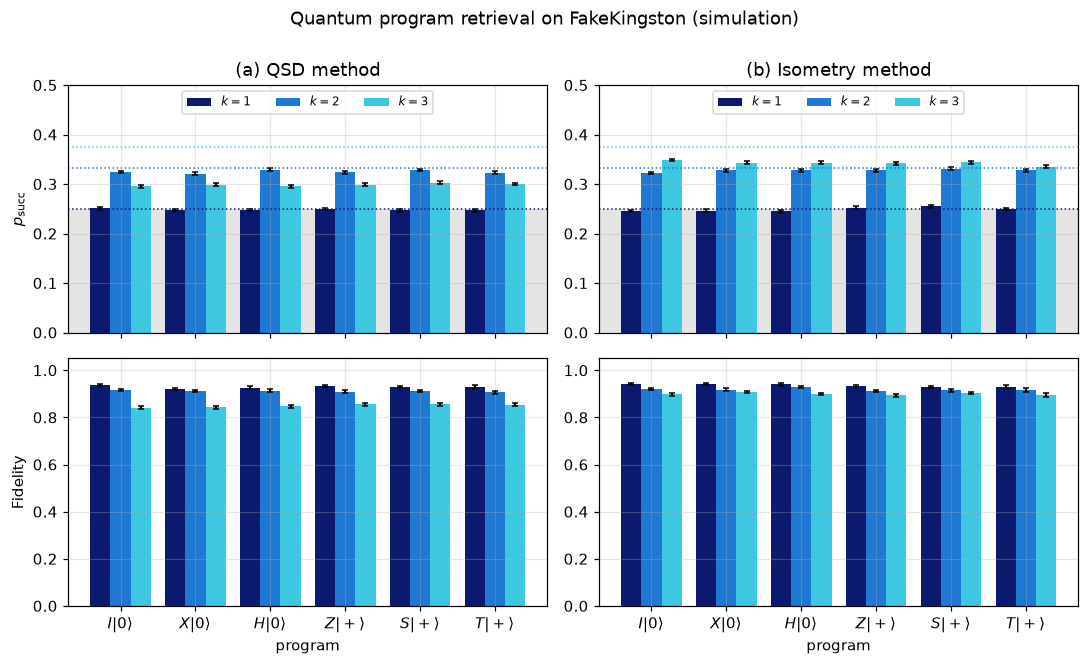

In [3]:
labels = [rf"${p}|{i}\rangle$" for p, i in COMBOS]
x = np.arange(len(COMBOS))
width = 0.27

fig, ax = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for col, method in enumerate(METHODS):
    for j, k in enumerate(KS_SAR):
        for row, key in ((0, "p"), (1, "F")):
            y = [res_sar[(method, k, p, i, "noisy")][key] for p, i in COMBOS]
            e = [res_sar[(method, k, p, i, "noisy")][key + "_err"] for p, i in COMBOS]
            ax[row, col].bar(x + (j - 1) * width, y, width, yerr=e, capsize=2,
                             color=K_COLORS[k], label=f"$k={k}$")
        ax[0, col].axhline(p_theory(k), color=K_COLORS[k], ls=":", lw=1)
    ax[0, col].axhspan(0, 0.25, color="lightgrey", alpha=0.6, lw=0, zorder=0)
    ax[0, col].set(title=f"({'ab'[col]}) {METHOD_STYLE[method]['label']} method", ylim=(0, 0.5))
    ax[1, col].set(ylim=(0, 1.05), xticks=x, xlabel="program")
    ax[1, col].set_xticklabels(labels)
    ax[0, col].legend(ncol=3, loc="upper center")
ax[0, 0].set_ylabel(r"$p_{\rm succ}$")
ax[1, 0].set_ylabel("Fidelity")
fig.suptitle("Quantum program retrieval on FakeKingston (simulation)", y=1.0)
fig.tight_layout()
plt.show()

## Optional: every program on all six Pauli eigenstates

The text states that each program is retrieved on all six Pauli eigenstates. Set the flag to `True` to
compute the input-averaged success probability and fidelity (about 6× the runtime above).

In [4]:
RUN_ALL_INPUTS = False

if RUN_ALL_INPUTS:
    PAULI_STATES = ["0", "1", "+", "-", "+i", "-i"]
    print(f"{'k':>2} {'method':<9} {'U':<2} | {'<p> noisy':>9} {'<F> noisy':>9}")
    print("-" * 40)
    for method in METHODS:
        for k in KS_SAR:
            for prog in PROGRAMS_1Q:
                runs = [run_single_qubit(k, method, "noisy", in_state=s, program=prog)
                        for s in PAULI_STATES]
                print(f"{k:>2} {method:<9} {prog:<2} | {np.mean([r['p'] for r in runs]):>9.4f} "
                      f"{np.mean([r['F'] for r in runs]):>9.4f}")